# 13. Project: Diffusion-Limited Aggregation

In this project you will develop a program to reproduce a famous model in computational physics, diffusion-limited aggregation (DLA). It simulates a wide range of physical systems including crystal growth [[video link](https://www.youtube.com/shorts/iFz6qQ9Txzc)], bacterial growth, and fluid dynamics. Through this exercise you'll also get to create your first fractal pattern. (Figure taken from https://physicstoday.scitation.org/doi/pdf/10.1063/1.1333284)

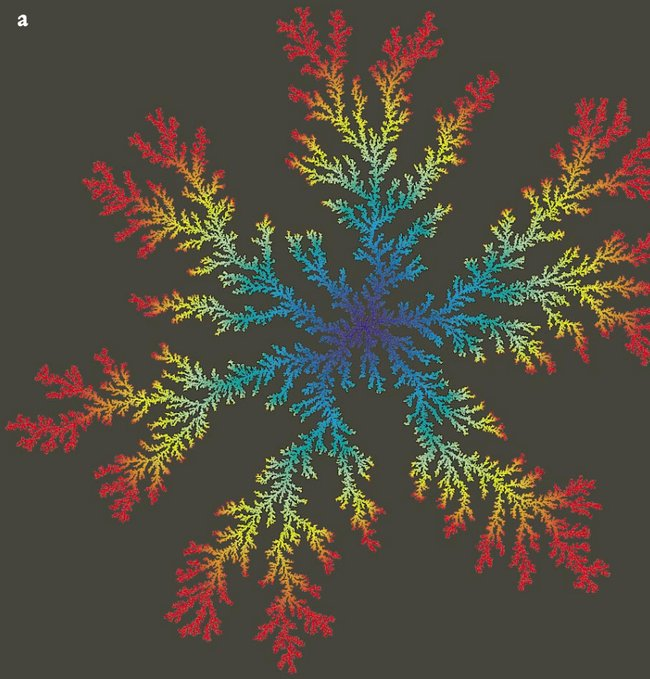

There are various versions of DLA, we'll try a simple version using 2D random walk on a square grid.

We start with a tiny cluster fixed near the origin. Every once in a while, a mobile particle that spawned from far way wanders near the cluster until it collides with the cluster, sticks to it, and remains there, no longer movable. The cluster thus grows bigger by one particle. Repeat this process many times, every time spawning a particle that performs random walk until it sticks, the cluster will continue to increase in size. Any pointy-finger parts of the cluster reaching out from the origin will have a higher chance of capturing the wandering particle, hence pointy parts becomes more pointy, and eventually the cluster will grow into a fractal shape similar to the figure above.

## Step 1a. 2D random walk

We will first implement a 2D random walk model on a square lattice for one particle with proper vectorization.

For every step in 2D, you'll make a choice between up, down, left, and right = [1,0], [0,-1], [-1,0], [0,1]. You may be tempted to write

```python
x_list = rng.choice([-1,1])
y_list = rng.choice([-1,1])
```

and stitch them together to form your steps, but then you'll run into diagonal steps like [1,1] every once in a while, which is not a valid move, so we have to find another way. One way is to generate a random array of *angles* (0, 90, 180, 270 degrees) all at once and then convert them into x and y components using array operations. A template following this approach is provided, but feel free to use any other time-efficient approach you prefer.

You can use for loops for prototyping and vectorize things later. **The final code should not contain any for loop**.

At the end, a plotting section is provided to show the trajectory of the particle and its starting / ending points in green / red. A sample image is attached.

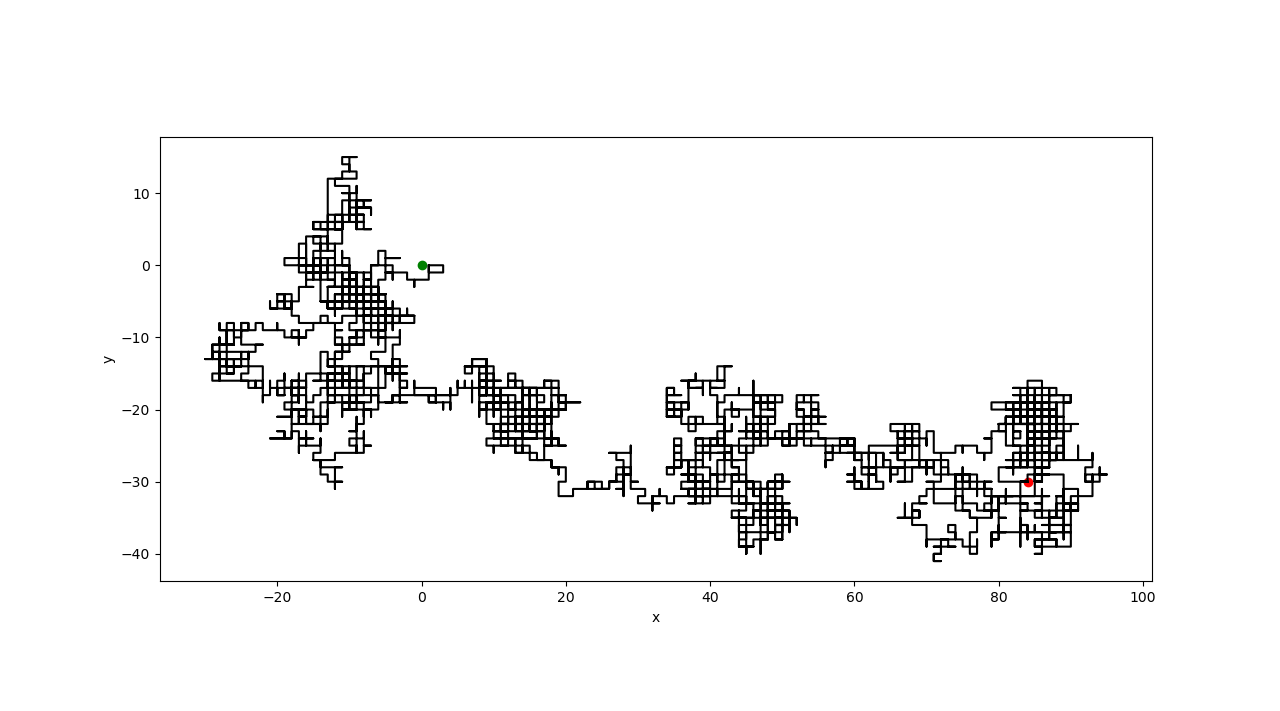



In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def rw2d(Nstep):
    """
    A simulation for 2D random walk for a single particle.
    Nstep = the number of steps each particle takes
    """

    Nstep=int(Nstep)
    rng = np.random.default_rng()

    # Individual steps in x and y
    angles =
    x_list = # a 1D array of dimensions Nstep
    y_list = # a 1D array of dimensions Nstep

    # x,y trajectories of the particle
    x_traj = # a 1D array of size Nstep using cumulative sum
    y_traj = # a 1D array of size Nstep using cumulative sum

    return x_traj, y_traj

x_traj, y_traj = rw2d(Nstep=1e4)

fig, ax1 = plt.subplots(1)
ax1.plot(0, 0, 'go')  #highlight the initial position
ax1.plot(x_traj[-1], y_traj[-1], 'ro')  #highlight the final position
ax1.plot(x_traj, y_traj, 'k-') #particle trajectory
ax1.set_aspect('equal', 'box')
plt.show()


## 1b. Random walk starting from `x0, y0`

Make a copy of the 2D Random Walk program that you wrote in Step 1a above as `rw2d()` in the template code. Modify it so that the particles trajectory starts from a coordinate `x0,y0`, instead of from the origin. The `rw2d()` function will return a 2D numpy array of dimensions `Nstep x 2`.

In [ ]:
def rw2d(x0,y0,Nstep):
    #Paste your single-particle random walk code here
    # that generates x_traj and y_traj starting from the origin

    #Generate the trajectories starting from x0 and y0
    x_traj_shifted =
    y_traj_shifted =

    #We will return a 2D array of dimensions Nstep x 2.
    # .T stands for taking the transpose
    return np.array([x_traj_shifted, y_traj_shifted]).T

## Step 2. Choosing the spawn radius

Set up a starting radius `spawn_radius` from which mobile particles will spawn and perform random walk. It needs to be far enough from the growing cluster so that there's enough space for the particle to wander around before it sticks; but not too far so that it wastes too much simulation time to wait for the particle to be captured.

To choose an appropriate `spawn_radius`, let's do the following. Among all the anchored and immovable particles belonging to the existing cluster, find the one with the furthest distance `cluster_max_radius` from the origin. A good `spawn_radius` is around `2*cluster_max_radius`. Note that this `spawn_radius` needs to grow as the cluster grows. Two schematic snapshots are given below.

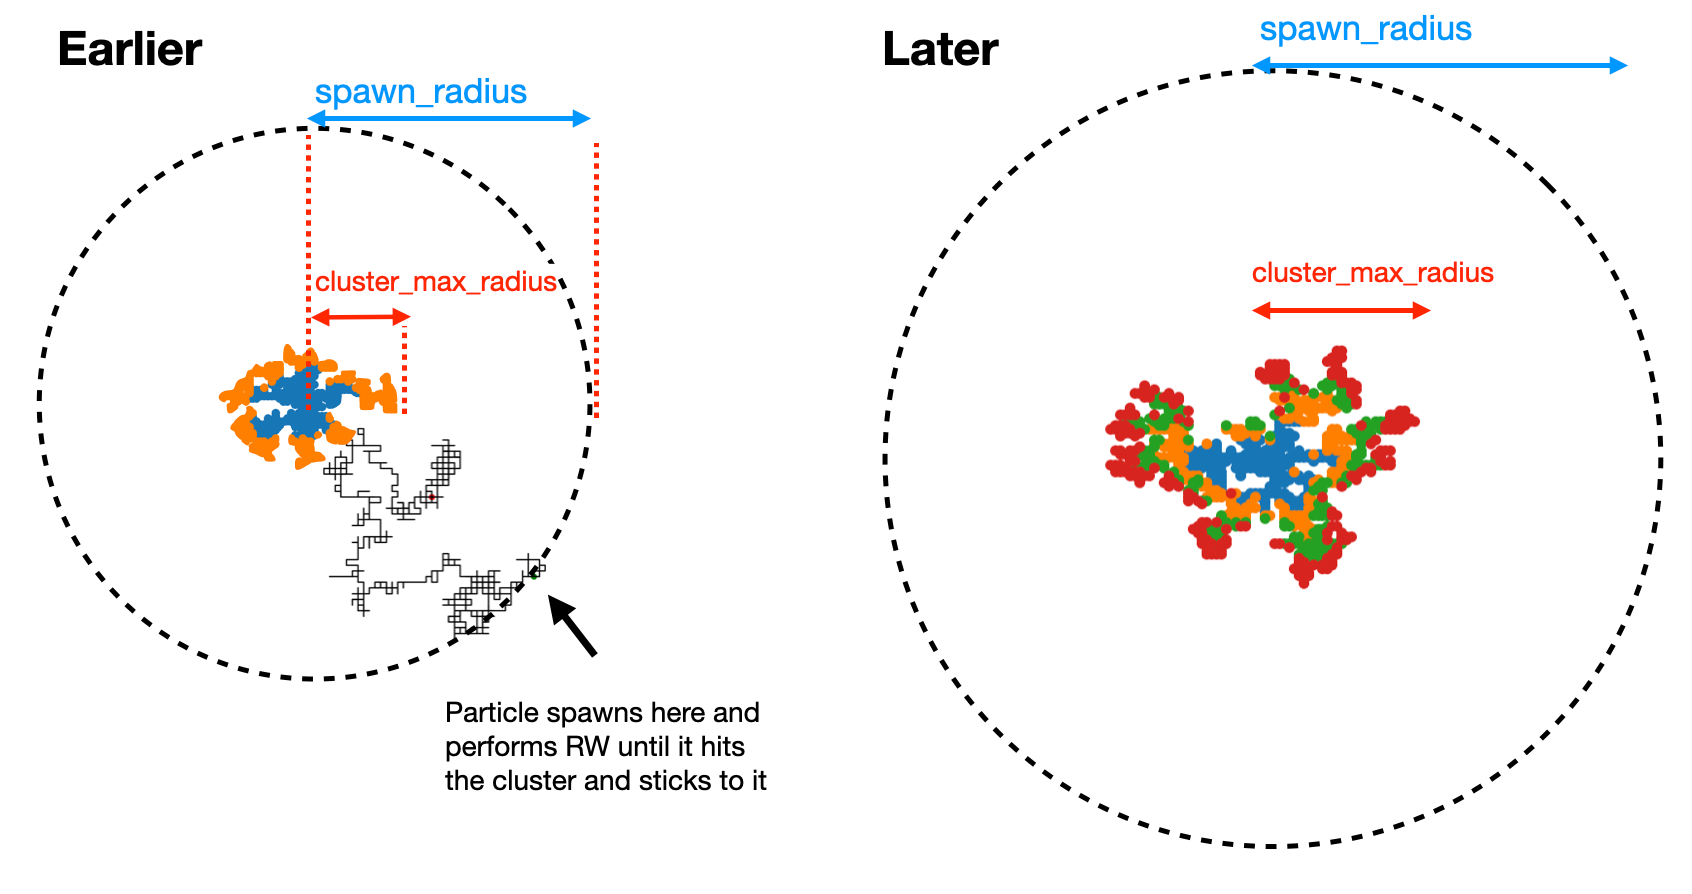

Fill in `cluster_max_radius` in the code below. The `cluster` is a 2D array of dimensions `ClusterSize x 2`. Column 0 holds the x coordinates and column 1 the y coordinates.

## Step 3. Spawning particles and growing the cluster

On top of a circle with radius = `spawn_radius` (which will keep increasing as the cluster grows), spawn particles randomly one at a time (in the for loop provided). **Convert the spawn coordinates to integers** so that it belongs to a square grid with step size 1. Then generate a trajectory for each spawned particle with 1e4 steps.

A `check_intersec()` function is provided to help you determine whether the trajectory hits the cluster at some step, so that we shall stick the mobile particle at that intersecting point. No need to worry about how `check_intersec()` works – similar to the style of group work we performed in class, all we need to know is what are the inputs and outputs of this function. Both are provided in the function's description text.

## Step 4a. Plotting the cluster

Plot the cluster you grew using points or circles. The shape should look fractal. Starting out, you can use fewer particles (e.g. 500) for quicker simulations and to debug your code. You can use the provided `print(int(i/Nparticle*100),'%')` line to monitor simulation progress to make sure that the simulation will not take forever.

## Step 4b. Plotting the cluster divided into groups
Divide your cluster data into five equal slices from the earliest to the latest arrivals. Plot each group of particles using a different color. You may either choose custom colors or simply run `plt.plot()` five times, which allows python to choose a different color every time by default. The final expected result is as follows, where we can visualize that the blue region arrived first and purple last.

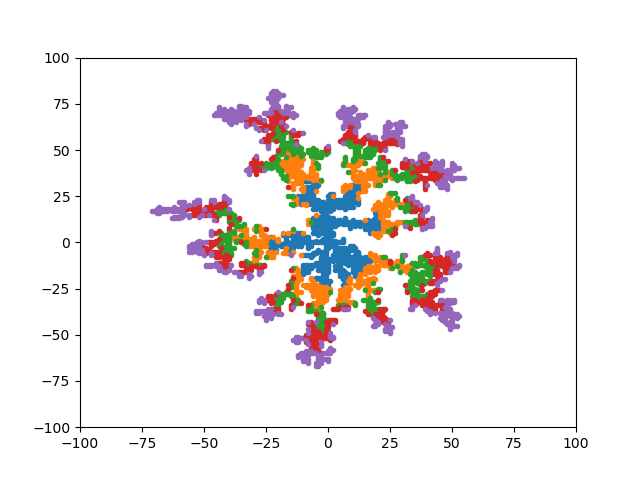

Store the five slices (each a 2D array, earliest arrivals first) in a list called `slices`, then plot them. With the small cluster here, the picture will be smaller than the one above.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def rw2d(x0,y0,Nstep):
    #1. Paste your single-particle random walk code here
    # that generates x_traj and y_traj starting from the origin

    #Generate the trajectories starting from x0 and y0
    x_traj_shifted =
    y_traj_shifted =

    #We will return a 2D array of dimensions Nstep x 2.
    # .T stands for taking the transpose
    return np.array([x_traj_shifted, y_traj_shifted]).T

def check_intersec(traj, cluster):
    """
    traj: a 2D array with dimensions Nsteps x 2. Needs to be all integers.
    cluster: a 2D array with dimensions Cluster Size x 2. Needs to be all integers.

    Description: This function searches for the first time traj intersects with cluster.

    Returns: the index of traj immediately before the intersection,
    i.e. the element in traj to be appended to the growing cluster.
    If there is no intersection, it returns -1.
    """
    traj    = np.around(traj).astype(int)
    cluster = np.around(cluster).astype(int)
    traj = traj[:,0]+traj[:,1]*1j
    cluster= cluster[:,0] + cluster[:,1]*1j

    intersec = np.where(np.isin(traj,  cluster ))[0]
    idx = -1 #default return value
    if len(intersec) > 0:
        idx = intersec[0] - 1
        #to prevent accidentally returning negative values
        if idx < 0 :
            idx = -1
    return idx

def dla():
    rng = np.random.default_rng()

    #This is our starting cluster, two particles at [0,0] and [0,1]
    cluster = np.array([[0,0],[0,1]])

    #Number of particles to be grown into our cluster. If wait times are long, start with fewer particles.
    Nparticle = 500
    for i in range(Nparticle):
        #A progress monitor
        if i%100==0: print(int(i/Nparticle*100),'%')

        #2. Setup a starting radius spawn_radius from which particles will spawn
        # and perform random walk.
        #It needs to be far enough from the growing cluster.
        #Among all the particles in the current cluster,
        #find the one with the furthest distance cluster_max_radius from the origin.
        #A good estimate for the radius of spawning particles is 2*cluster_max_radius.
        cluster_max_radius =
        spawn_radius = 2*cluster_max_radius

        #3. Generate a random spawn coordinate x0,y0 somewhere on spawn_radius
        #and convert them into integers,
        #since check_intersec() only works for integers.
        x0 =
        y0 =

        #Generate random walk trajector starting from x0,y0
        #We'll try 10000 steps for each particle.
        traj = rw2d(x0,y0,1e4)

        #This is a provided function that finds the correct coordinate
        # where the particle sticks to the growing cluster.
        # Takes 2D arrays of dimensions Nstep x 2 and ClusterSize x 2 as input.
        #No need to worry about how it works.
        idx = check_intersec(traj, cluster)
        if idx >0:
            cluster = np.append(cluster, [traj[idx]],axis=0)

    r=100
    plt.figure()
    plt.xlim(-r,r)
    plt.ylim(-r,r)

    #4. Finish the plotting section
    plt.plot(..., ...,  marker='.', linestyle='')
    plt.show()

    return cluster

cluster = dla()

## Step 5. Put it all together

Now run your code with `Nparticle = 10000`

## Step 6. Fractal dimension

In class we demonstrated two general methods to calculate the fractal dimension of a given shape. In this Problem we will show that, for the typical fractal "dendritic-shaped" pattern formed in diffusion limited aggregation in Exam 3, its fractal dimension is 1.7 - the finger-like structures may remind you of one-dimensional shapes, but there are so many fingers trying to fill up a two-dimensional plane, so it is intuitive to expect that the fractal dimension is somewhere between 1 and 2.

We will use the first method discussed in class to show this. Using your DLA code from Step 5 (the `cluster` it returned), calculate the number of particles n within a given radius r, as a function of r (see the figure below). If the shape is fully two dimensional (e.g. a filled circular disk), then n should scale as $\pi r^2$. If the shape is one dimensional (e.g. a bar or line shape), then n should scale as r. We can therefore make a generalized statement that for an arbitrary shape, n scales as $r^D$, where D is the dimension of the shape.

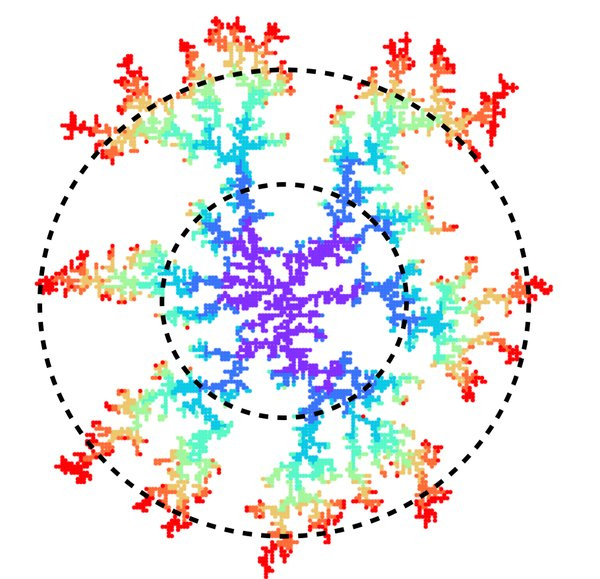

### 6a. Counting particles within radius r

Calculate n for a range of r values.

In [ ]:
#Distance of every particle in the cluster from the origin
dist =

#A range of radii, from 1 up to the edge of the cluster
r_list = np.arange(1, dist.max()+1)

#n_list[k] = number of particles within radius r_list[k]
n_list =

### 6b. Log-log plot

Since $n = C r^D$ (where C is some constant), $\log(n) = \log(C) + D\log(r)$. So if we plot log(n) versus log(r), the slope will be D. Draw several lines with slopes ranging from 1.5 to 2 and show that D is around 1.7. A quick example figure is attached showing slopes of 1.6, 1.7 and 1.8.

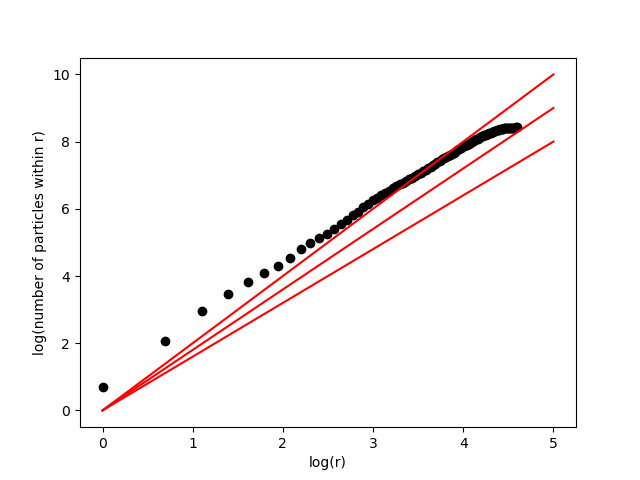

*If you know how to do linear fits that's fine too. But that's not required.

In [ ]:
plt.figure()

#Plot log(n) versus log(r) as black dots
plt.plot(..., ..., 'ko')

#Draw several lines with slopes ranging from 1.5 to 2


plt.xlabel('log(r)')
plt.ylabel('log(number of particles within r)')
plt.show()

**What is the fractal dimension D of your cluster?** Write your answer here, and say which part of the curve you used.